# XGBoost — feature ingegnerizzate e raw (vettore piatto)
Gradient boosting multiclasse su 94 feature e sul raw appiattito `(n, 3*T)` con padding a zero, come RF/SVM/CatBoost (UniZgFall e UniMiB). Dipendenza: `xgboost`. I risultati sono separati in `results/advanced/` o `results/advanced/quick/`, con prefisso `modello_dataset_rappresentazione_cv`.

In [1]:
import config as cfg, utils, advanced_models as adv
utils.print_versions()
adv.print_versions()
utils.print_config()
print('XGBOOST_PARAMS:', cfg.XGBOOST_PARAMS)
MODEL = 'xgboost'

Python      : 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
numpy       : 2.5.4
pandas      : 3.0.6
scipy       : 1.18.1
sklearn     : 1.9.1
catboost    : 1.2.10
matplotlib  : 3.11.2
natsort     : 8.4.0
tqdm        : 4.70.1
Python: 3.12.13 | Linux-7.0.0-38-generic-x86_64-with-glibc2.39
xgboost: 3.4.1
sktime: 1.2.0
torch: 2.14.1
SEED=89  N_SPLITS=10  CV_MODE=stratified  QUICK_TEST=False
FALL_CLASSES: {'UniMiB': [9, 10, 11, 12, 13, 14, 15, 16], 'UniZgFall': [5, 6, 7]}
XGBOOST_PARAMS: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'objective': 'multi:softprob', 'eval_metric': 'mlogloss', 'tree_method': 'hist', 'device': 'cuda', 'random_state': 89, 'n_jobs': 1}


## Cross-validation, metriche e predizioni

In [2]:
adv.run_all(MODEL)

[xgboost | UniZgFall | features] risultati già presenti, salto (xgboost_UniZgFall_features_stratified_folds.csv).
[xgboost | UniZgFall | raw] risultati già presenti, salto (xgboost_UniZgFall_raw_stratified_folds.csv).
[xgboost | UniMiB | features] risultati già presenti, salto (xgboost_UniMiB_features_stratified_folds.csv).
[xgboost | UniMiB | raw] X=(1980, 9624), classi=17, CV=stratified, fold=10
Parametri: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'objective': 'multi:softprob', 'eval_metric': 'mlogloss', 'tree_method': 'hist', 'device': 'cuda', 'random_state': 89, 'n_jobs': 1}


xgboost|UniMiB:   0%|          | 0/10 [00:00<?, ?it/s]

[xgboost | UniMiB | raw | fold 1/10] train su 1782 esempi, test su 198
fit in corso...


[xgboost | UniMiB | raw | fold 1/10] fit 79.30s | predict 0.09s | acc 0.5404 | F1 macro 0.5562
[xgboost | UniMiB | raw | fold 2/10] train su 1782 esempi, test su 198
fit in corso...


/home/agrume/Desktop/projects/thesis/.venv/lib/python3.12/site-packages/xgboost/core.py:569: UserWarning: [17:54:03] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


[xgboost | UniMiB | raw | fold 2/10] fit 78.36s | predict 0.10s | acc 0.4798 | F1 macro 0.4881
[xgboost | UniMiB | raw | fold 3/10] train su 1782 esempi, test su 198
fit in corso...
[xgboost | UniMiB | raw | fold 3/10] fit 80.80s | predict 0.10s | acc 0.5303 | F1 macro 0.5310
[xgboost | UniMiB | raw | fold 4/10] train su 1782 esempi, test su 198
fit in corso...
[xgboost | UniMiB | raw | fold 4/10] fit 67.58s | predict 0.10s | acc 0.5404 | F1 macro 0.5766
[xgboost | UniMiB | raw | fold 5/10] train su 1782 esempi, test su 198
fit in corso...
[xgboost | UniMiB | raw | fold 5/10] fit 81.11s | predict 0.10s | acc 0.5101 | F1 macro 0.4943
[xgboost | UniMiB | raw | fold 6/10] train su 1782 esempi, test su 198
fit in corso...
[xgboost | UniMiB | raw | fold 6/10] fit 66.80s | predict 0.10s | acc 0.5051 | F1 macro 0.5113
[xgboost | UniMiB | raw | fold 7/10] train su 1782 esempi, test su 198
fit in corso...
[xgboost | UniMiB | raw | fold 7/10] fit 81.17s | predict 0.10s | acc 0.5202 | F1 macro 0.

## Riepilogo

In [3]:
display(adv.summary_table(MODEL))

,dataset,input,accuracy,f1_macro,precision_macro,recall_macro,fit_time,predict_time,fall_sensitivity,fall_specificity,fall_precision
0,UniZgFall,features,0.9145 ± 0.0266,0.8935 ± 0.0445,0.9135 ± 0.0504,0.8967 ± 0.0391,1.8123 ± 0.0662,0.0015 ± 0.0001,0.9609 ± 0.0691,0.9946 ± 0.0114,0.9818 ± 0.0383
1,UniZgFall,raw,0.7348 ± 0.0787,0.6574 ± 0.1100,0.6888 ± 0.1122,0.6769 ± 0.1092,225.6752 ± 9.3277,0.0047 ± 0.0030,0.7736 ± 0.1248,0.9670 ± 0.0341,0.8751 ± 0.1098
2,UniMiB,features,0.6884 ± 0.0320,0.7400 ± 0.0234,0.7525 ± 0.0206,0.7422 ± 0.0253,10.9519 ± 0.1105,0.0115 ± 0.0041,0.9986 ± 0.0029,0.9944 ± 0.0125,0.9979 ± 0.0046
3,UniMiB,raw,0.5338 ± 0.0338,0.5432 ± 0.0382,0.5644 ± 0.0446,0.5467 ± 0.0376,75.5275 ± 6.4535,0.0987 ± 0.0029,0.9979 ± 0.0034,0.9889 ± 0.0129,0.9959 ± 0.0048


## Grafici e importanza delle feature

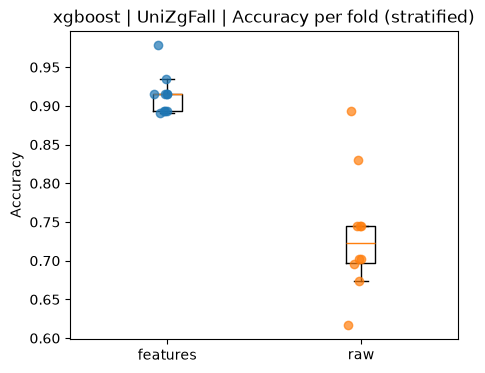

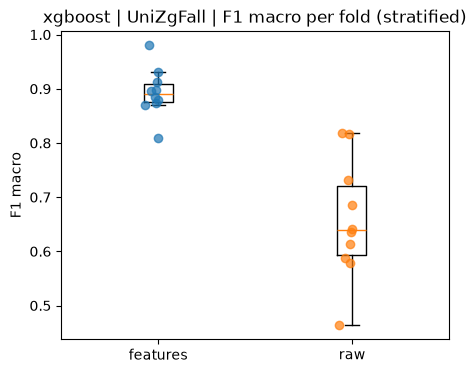

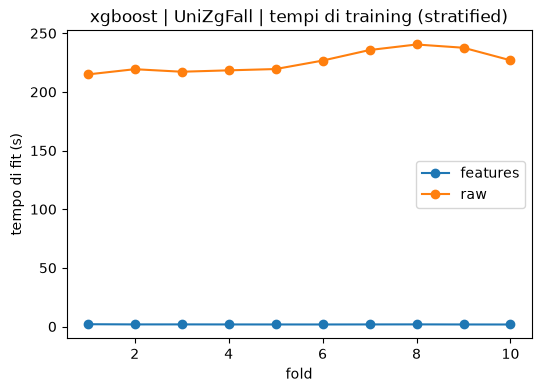

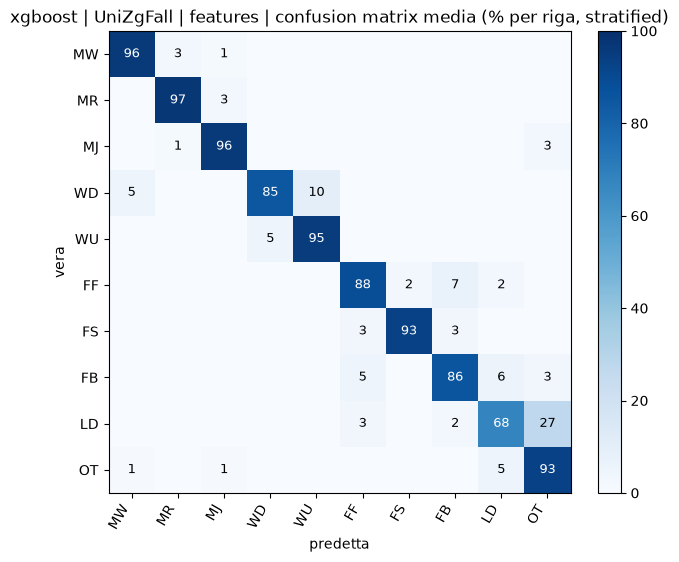

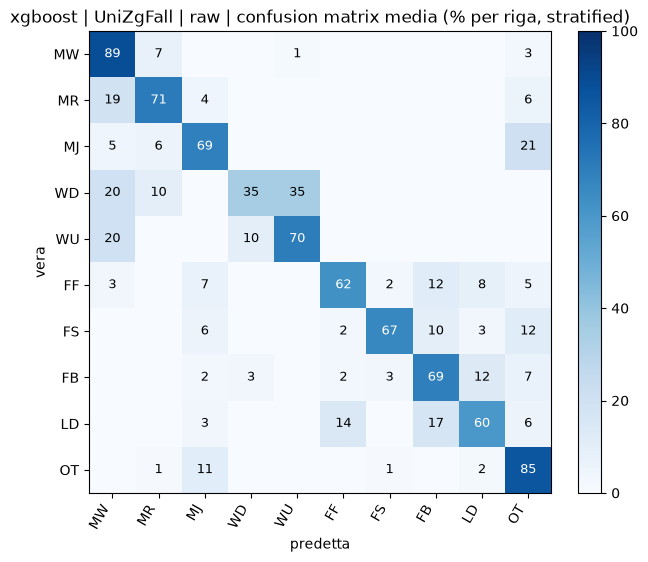

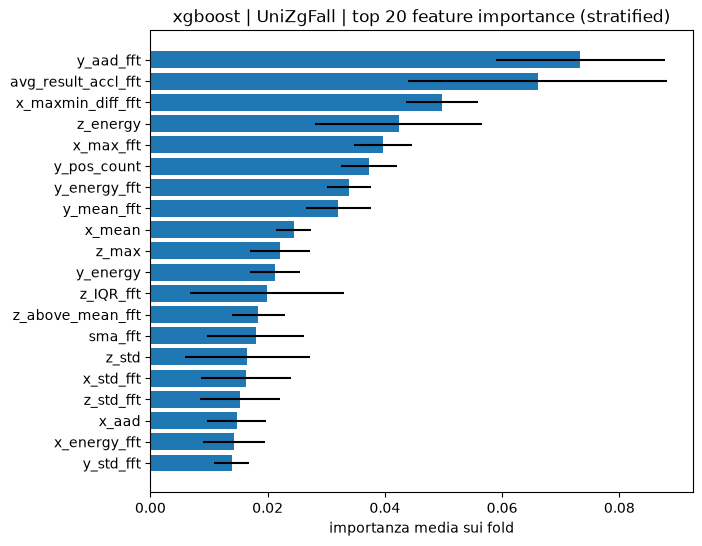

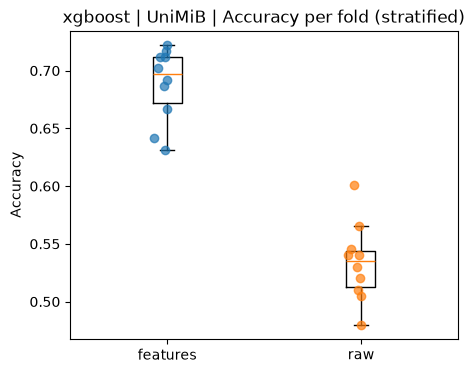

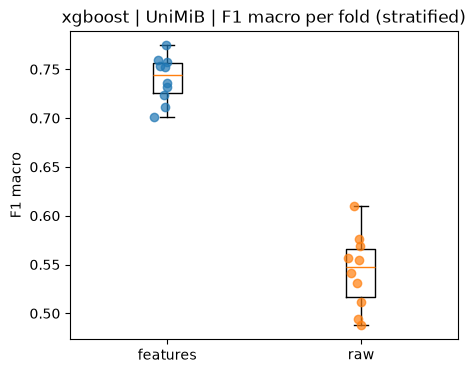

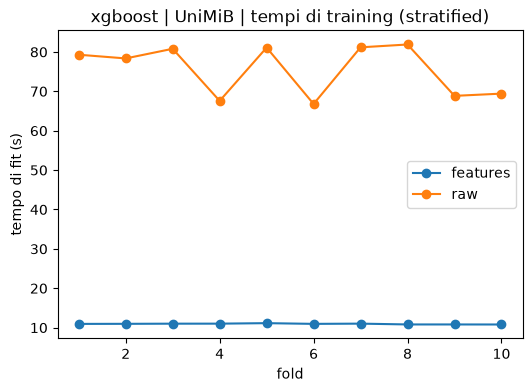

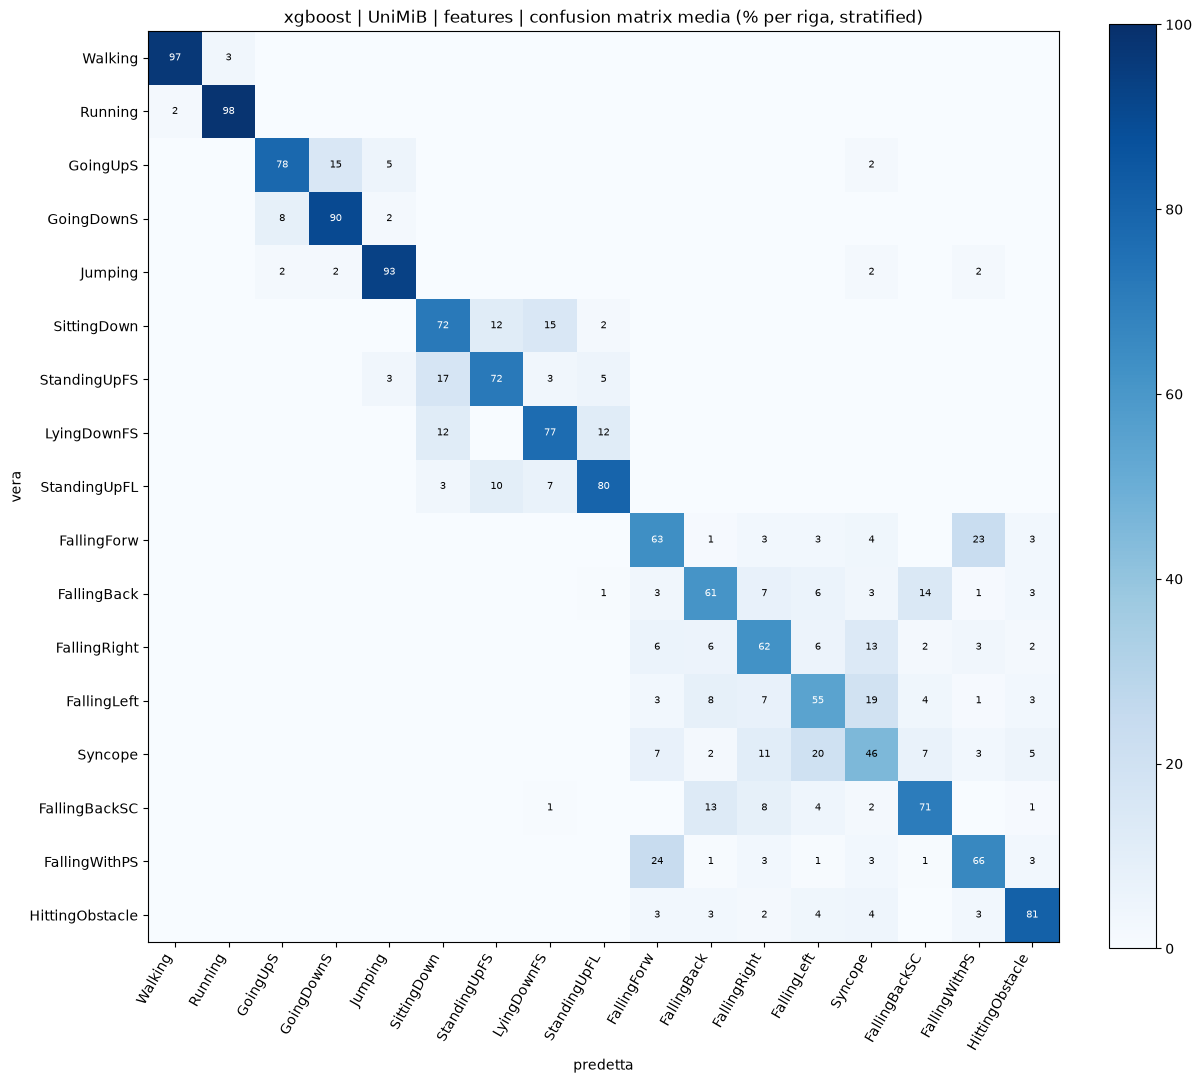

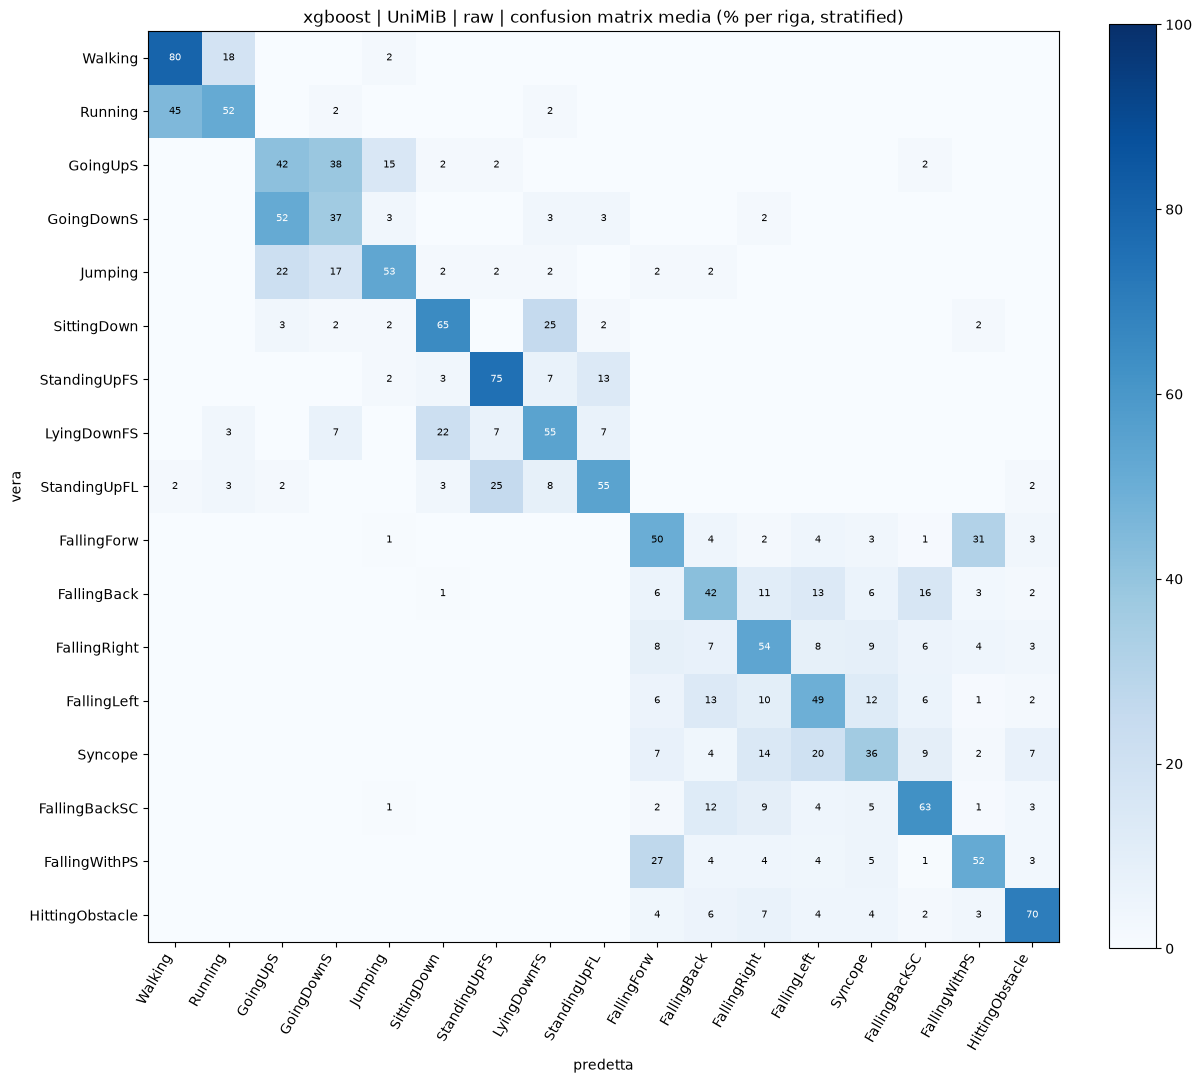

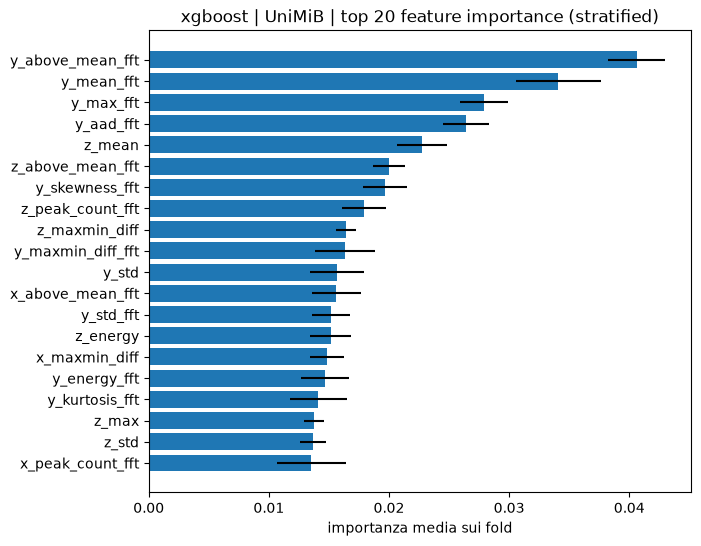

In [4]:
adv.plot_all(MODEL)